# MediaPipe baseline — 3DPW

For our project, I tested MediaPipe on **20 frames spread across** the `downtown_arguing_00` sequence. I used **Person 0** and compared 10 joints: shoulders, elbows, wrists, knees, and ankles.

This notebook shows **preliminary PA-MPJPE**, not a verified benchmark. MediaPipe and 3DPW use different 3D coordinate conventions and slightly different joint definitions. We need to agree on those details with the team before calculating standard MPJPE or comparing the final refined results.

Run cells from top to bottom in Google Colab. The private 3DPW files stay in Google Drive, not GitHub.

In [1]:
# Colab may need this after a runtime reset
%pip -q install mediapipe

In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pickle
import zipfile
import sys
import requests
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import mediapipe as mp

# Where I saved the 3DPW dataset
root = Path('/content/drive/MyDrive/3D Pose Project/3DPW')
sequence_path = root / 'sequenceFiles/test/downtown_arguing_00.pkl'
image_zip = root / 'imageFiles.zip'
image_folder = root / 'spread_images'
image_folder.mkdir(parents=True, exist_ok=True)

if not sequence_path.exists():
    raise FileNotFoundError(f'Missing dataset file: {sequence_path}')

with open(sequence_path, 'rb') as f:
    data = pickle.load(f, encoding='latin1')

print('Sequence:', data['sequence'])
print('Number of people:', len(data['jointPositions']))

Mounted at /content/drive
Sequence: downtown_arguing_00
Number of people: 2


In [3]:
# Download the model and load our metrics.py file
model_path = Path('/content/pose_landmarker.task')
model_url = ('https://storage.googleapis.com/mediapipe-models/'
             'pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task')
if not model_path.exists() or model_path.stat().st_size < 1_000_000:
    response = requests.get(model_url, timeout=120)
    response.raise_for_status()
    model_path.write_bytes(response.content)

# This file is on my GitHub branch; change the URL after the pull request is merged
metrics_url = ('https://raw.githubusercontent.com/elifdilabayrak/'
               'Computer-Vision-Applied-Project/patch-1/'
               '3d-pose-diff-render/src/metrics.py')
response = requests.get(metrics_url, timeout=60)
response.raise_for_status()
metrics_source = response.text.lstrip()  # Earlier GitHub version had spaces on line 1
compile(metrics_source, 'metrics.py', 'exec')
Path('/content/metrics.py').write_text(metrics_source)
sys.path.insert(0, '/content')
sys.modules.pop('metrics', None)
from metrics import mpjpe, pa_mpjpe

options = mp.tasks.vision.PoseLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(model_asset_path=str(model_path)),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_poses=1
)
print('MediaPipe and metrics are ready')

MediaPipe and metrics are ready


In [4]:
# Pick 20 frames across the video instead of 20 frames in a row
person_id = 0
frame_count = len(data['jointPositions'][person_id])
frame_ids = np.linspace(0, frame_count - 1, 20, dtype=int)

# Get the selected images from the ZIP if they are not already in Drive
missing = [int(i) for i in frame_ids
           if not (image_folder / f'image_{i:05d}.jpg').exists()]
if missing:
    if not image_zip.exists():
        raise FileNotFoundError(f'Missing image archive: {image_zip}')
    with zipfile.ZipFile(image_zip) as z:
        for frame in missing:
            member = f'imageFiles/downtown_arguing_00/image_{frame:05d}.jpg'
            (image_folder / f'image_{frame:05d}.jpg').write_bytes(z.read(member))

# Joint orders must match
mp_ids = [11, 12, 13, 14, 15, 16, 25, 26, 27, 28]
smpl_ids = [16, 17, 18, 19, 20, 21, 4, 5, 7, 8]
print('Frames selected:', frame_ids.tolist())

Frames selected: [0, 47, 94, 141, 188, 236, 283, 330, 377, 424, 472, 519, 566, 613, 660, 708, 755, 802, 849, 897]


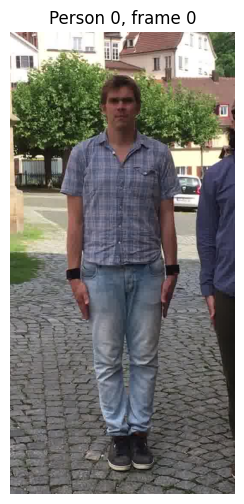

In [5]:
# Crop the person using 3DPW's 2D joints
# We use the full image height so feet do not get cut off.
def crop_person(image_rgb, frame, padding=150):
    joints = np.asarray(data['poses2d'][person_id][frame])
    x, y, confidence = joints
    valid = (confidence > 0) & np.isfinite(x)
    if not valid.any():
        return None

    width = image_rgb.shape[1]
    x1 = max(0, int(np.min(x[valid])) - padding)
    x2 = min(width, int(np.max(x[valid])) + padding)
    if x2 <= x1:
        return None
    return image_rgb[:, x1:x2]

# Show one example
frame = int(frame_ids[0])
image = cv2.imread(str(image_folder / f'image_{frame:05d}.jpg'))
if image is None:
    raise FileNotFoundError('First image could not be opened')
example = crop_person(cv2.cvtColor(image, cv2.COLOR_BGR2RGB), frame)
if example is None:
    raise RuntimeError('Could not crop Person 0 in the first frame')
plt.figure(figsize=(5, 6))
plt.imshow(example)
plt.title(f'Person 0, frame {frame}')
plt.axis('off')
plt.show()

In [6]:
# Run MediaPipe and calculate the preliminary aligned error
rows = []
failed_frames = []
examples = {}
show_frames = {int(frame_ids[i]) for i in [0, 4, 8, 12, 16, 19]}

with mp.tasks.vision.PoseLandmarker.create_from_options(options) as detector:
    for frame in frame_ids:
        frame = int(frame)
        image = cv2.imread(str(image_folder / f'image_{frame:05d}.jpg'))
        if image is None:
            failed_frames.append(frame)
            continue
        rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        cropped = crop_person(rgb, frame)
        if cropped is None:
            failed_frames.append(frame)
            continue

        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB,
                            data=np.ascontiguousarray(cropped))
        detection = detector.detect(mp_image)
        if not detection.pose_world_landmarks or not detection.pose_landmarks:
            failed_frames.append(frame)
            continue

        landmarks = detection.pose_world_landmarks[0]
        predicted = np.array([[landmarks[j].x, landmarks[j].y, landmarks[j].z]
                              for j in mp_ids])
        ground_truth = np.asarray(data['jointPositions'][person_id][frame]).reshape(24, 3)[smpl_ids]
        error_mm = pa_mpjpe(predicted, ground_truth)
        rows.append({'frame': frame, 'pa_mpjpe_mm': error_mm})

        if frame in show_frames:
            examples[frame] = (cropped, detection.pose_landmarks[0])

results_df = pd.DataFrame(rows, columns=['frame', 'pa_mpjpe_mm'])
print('Frames evaluated:', len(results_df), '/', len(frame_ids))
print('Frames skipped:', failed_frames)
if results_df.empty:
    raise RuntimeError('MediaPipe did not detect any usable frames')
print('Preliminary mean PA-MPJPE:', round(results_df['pa_mpjpe_mm'].mean(), 2), 'mm')
print('Minimum:', round(results_df['pa_mpjpe_mm'].min(), 2), 'mm')
print('Maximum:', round(results_df['pa_mpjpe_mm'].max(), 2), 'mm')

Frames evaluated: 20 / 20
Frames skipped: []
Preliminary mean PA-MPJPE: 82.07 mm
Minimum: 38.37 mm
Maximum: 162.85 mm


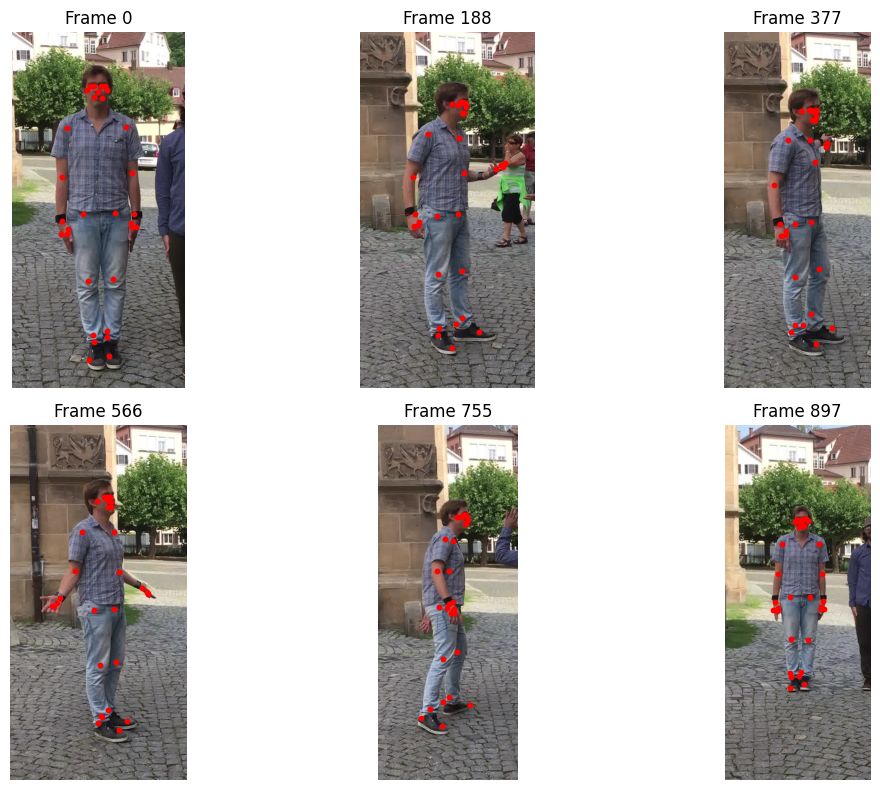

In [7]:
# Check that the red landmarks are on the correct person
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, frame in zip(axes.flat, sorted(examples)):
    cropped, landmarks = examples[frame]
    ax.imshow(cropped)
    ax.scatter([p.x * cropped.shape[1] for p in landmarks],
               [p.y * cropped.shape[0] for p in landmarks], s=10, c='red')
    ax.set_title(f'Frame {frame}')
    ax.axis('off')
for ax in axes.flat[len(examples):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

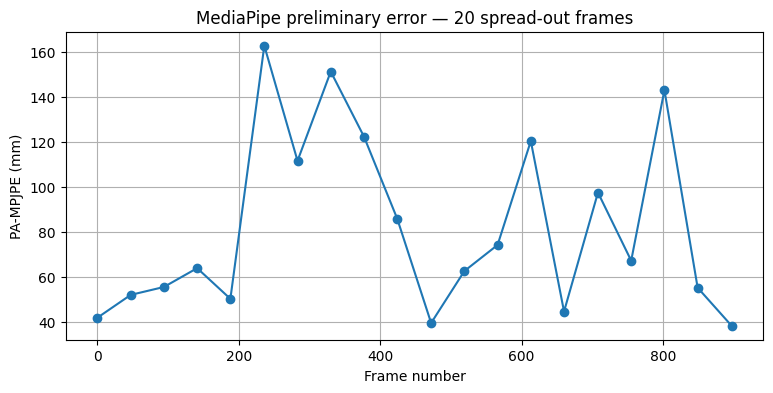

CSV saved: /content/drive/MyDrive/3D Pose Project/mediapipe_spread20_preliminary.csv
Graph saved: /content/drive/MyDrive/3D Pose Project/mediapipe_spread20_preliminary.png
Highest errors:
 frame  pa_mpjpe_mm
   236   162.845448
   330   151.352191
   802   143.127387
   377   122.428980
   613   120.467183


In [8]:
# Save the updated results and graph without overwriting the old test
output_dir = root.parent
csv_path = output_dir / 'mediapipe_spread20_preliminary.csv'
plot_path = output_dir / 'mediapipe_spread20_preliminary.png'
results_df.to_csv(csv_path, index=False)

plt.figure(figsize=(9, 4))
plt.plot(results_df['frame'], results_df['pa_mpjpe_mm'], marker='o')
plt.xlabel('Frame number')
plt.ylabel('PA-MPJPE (mm)')
plt.title('MediaPipe preliminary error — 20 spread-out frames')
plt.grid(True)
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print('CSV saved:', csv_path)
print('Graph saved:', plot_path)
print('Highest errors:')
print(results_df.nlargest(5, 'pa_mpjpe_mm').to_string(index=False))

### What Still Needs Checking

So far, MediaPipe worked on all 20 frames, and the average PA-MPJPE was 82.07 mm.

Before using this as our final result, we still need to:

- Make sure MediaPipe and 3DPW are comparing the same body joints.
- Check that their 3D coordinates are measured in the same way.
- Calculate MPJPE along with PA-MPJPE.
- Make sure our teammates use the same frames and joints so we can fairly compare the results before and after refinement.

For now, these are our preliminary results.